# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
from time import time
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *
from sources.finitevolume import *

# Generate data

In [29]:
X_r, X_data, u_data = gen_train_data(100_000,1_000,1_000)

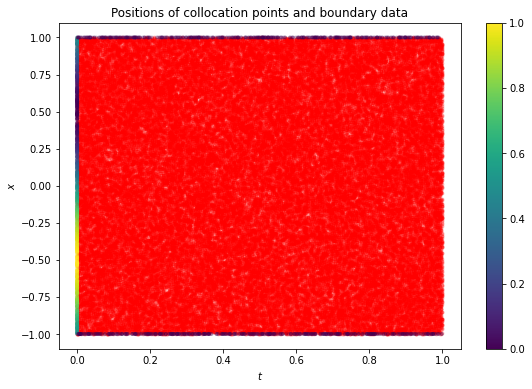

In [30]:
plot_train_data(X_r, X_data, u_data)

In [31]:
X_r = X_r[:,:2]
X_data[0] = X_data[0][:,:2]
X_data[1] = X_data[1][:,:2]

# Training

In [32]:
model = PhysicsInformedNN(lb, ub, output_dim=1, num_hidden_layers=8, num_neurons_per_layer=20, activation='tanh')
model.build(input_shape=(None,2))

solver = PINNSolver(model, batch_size = 5_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=100,
    decay_rate=0.98,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data, alpha = 1.)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('burgers')

Epoch 02_300: phi_r  1.6324e-01    phi_0  3.2913e-03    phi_b  8.3021e-04    total_loss  1.6736e-01
Training time: 168.95395350456238 seconds


<AxesSubplot:xlabel='Iteration', ylabel='Loss'>

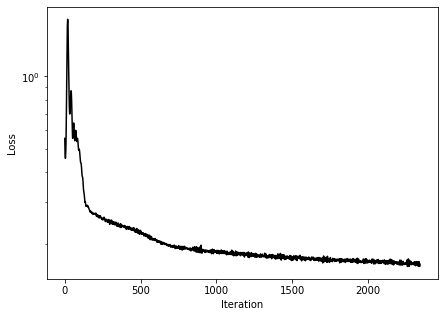

In [33]:
solver.plot_loss_history()

# Check results

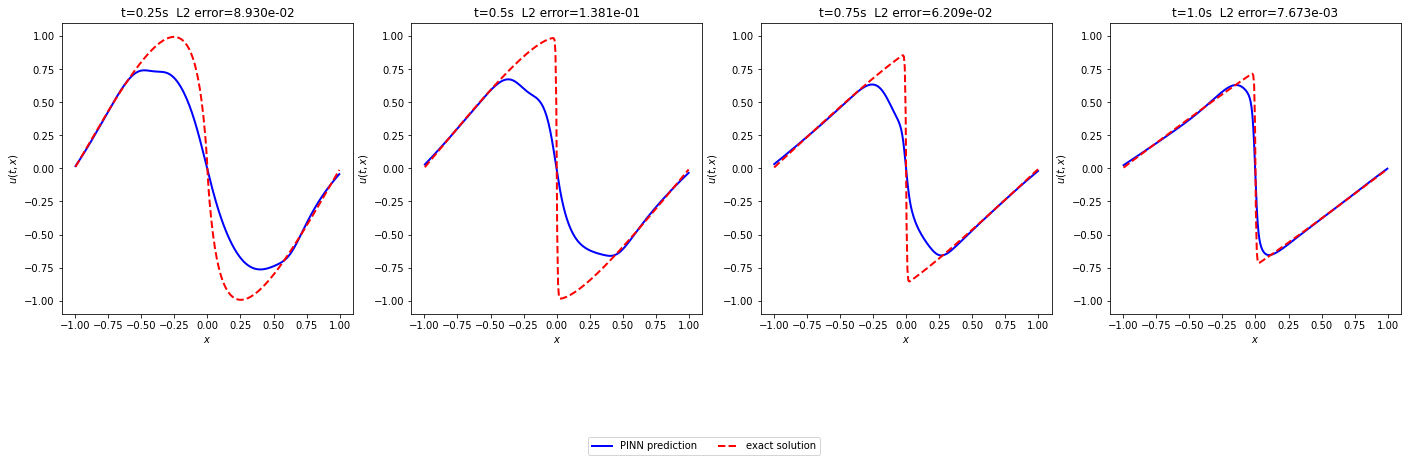

In [34]:
all_times = [0.25, 0.5, 0.75, 1.0]
exact_solutions = []
N = 300

# initialize exact solver
bg=EDP(N, viscosity.numpy() , u_0)
x = bg.cells[bg.begin:bg.end]

# compute exact solution 
for i_t, end_time in enumerate(all_times):
  bg.init()
  sol=bg.solve(end_time)
  exact_solutions.append(sol[-1])

fig, ax = plt.subplots(1, 4, figsize=(24, 8))

for i_t, end_time in enumerate(all_times):

    exact_sol = exact_solutions[i_t]

    # PINN prediction
    T, X = np.meshgrid(end_time, x)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))
    upred = tf.reshape(upred, (1,N))[0].numpy()

    # plot 
    erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
    title = "t={}s  L2 error={:5.3e}".format(end_time, erreurL2)
    ax[i_t].set_title(title)

    ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
    ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

    ax[i_t].set_xlabel('$x$')
    ax[i_t].set_ylabel('$u(t,x)$')    
    ax[i_t].axis('square')
    ax[i_t].set_xlim([-1.1,1.1])
    ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2);